In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
#IMPORTED ALL LIBRARIES REQUIRED FOR THE PROJECT



pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42
# prepares the project folders, configures how data tables and plots are displayed,


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")
    # saves the current Matplotlib plot as a PNG image in the figures folder

c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv("AI_Usage_and_Impact_on_Students_and_Professionals.csv")
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")
#Read a dataset and print the number of rows and columns in the dataset.

Loaded 300 rows and 19 columns


In [3]:
raw_path = DATA_DIR / "ai_usage_raw.csv"   #name of the raw dataset file
if not raw_path.exists():
    df.to_csv(raw_path, index=False)
    print(f"Raw data saved to {raw_path}")
    # saves the raw dataset to a CSV file in the data folder if it doesn't already exist

In [4]:
df.head()
# displays the first few rows of the dataset to give an overview of its structure and contents.

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.30,4.00,7.00,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.90,3.00,9.00,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.20,2.00,4.00,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.60,4.00,5.00,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.70,4.00,7.00,9.2,6.2,Yes


In [5]:
df.info()
# provides a concise summary of the dataset, including the number of non-null entries and data types for each column.

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    str    
 1   Age                          277 non-null    str    
 2   Gender                       290 non-null    str    
 3   Country                      290 non-null    str    
 4   User_Type                    300 non-null    str    
 5   Education_Level              287 non-null    str    
 6   Profession                   285 non-null    str    
 7   Monthly_Income               290 non-null    str    
 8   AI_Tool                      289 non-null    str    
 9   AI_Purpose                   287 non-null    str    
 10  AI_Usage_Hours_Per_Day       293 non-null    str    
 11  Tasks_Performed              282 non-null    str    
 12  Monthly_AI_Cost              288 non-null    str    
 13  Productivity_Score           28

In [6]:
df.describe(include="all").T
# provides descriptive statistics for each column in the dataset, including count, mean, standard deviation, min, max, and percentiles for numerical columns, and unique values and top frequency for categorical columns.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
User_ID,300,288,U0138,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,277,52,23,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,290,11,Male,122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,290,20,India,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
User_Type,300,2,Student,158,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education_Level,287,16,Bachelor's,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profession,285,126,English Literature Student,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly_Income,290,233,0,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI_Tool,289,16,ChatGPT,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI_Purpose,287,8,Coding,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.isna().sum()
# checks for missing values in each column of the dataset and returns the count of missing values for each column.

User_ID                         0
Age                            23
Gender                         10
Country                        10
User_Type                       0
Education_Level                13
Profession                     15
Monthly_Income                 10
AI_Tool                        11
AI_Purpose                     13
AI_Usage_Hours_Per_Day          7
Tasks_Performed                18
Monthly_AI_Cost                12
Productivity_Score             16
Accuracy_Rating                15
Satisfaction_Score              7
Time_Saved_Hours_Per_Week      10
Work_or_Study_Hours_Per_Day     9
Would_Recommend                 5
dtype: int64

In [8]:
df_clean = df.copy()

In [9]:
new_names = {
    "User_ID": "user_id",
    "Age": "age",
    "Gender": "gender",
    "Country": "country",
    "Education_Level": "education_level",
    "User_Type": "user_type",
    "Profession": "profession",
    "Monthly_Income": "monthly_income", 
    "AI_Tools": "ai_tools",
    "AI_Purpose": "ai_purpose",
    "AI_Usage_Hours_Per_Day": "ai_usage_hours_per_day",
    "Tasks_Performed" : "tasks_performed",
    "Monthly_AI_Cost": "monthly_ai_cost",
    "Productivity_Score": "productivity_score",
    "Accuracy_Rating": "accuracy_rating",
    "Satisfaction_Score": "satisfaction_score",
    "Time_Saved_Hours_Per_Week": "time_saved_hours_per_week",
    "Work_or_Study_Hours_Per_Day": "work_or_study_hours_per_day",
    "Would_Recommend" : "would_recommend",
}
df_clean = df_clean.rename(columns=new_names)
df_clean.columns.tolist()    
# renames the columns of the dataset to more user-friendly names and displays the list of new column names.

['user_id',
 'age',
 'gender',
 'country',
 'user_type',
 'education_level',
 'profession',
 'monthly_income',
 'AI_Tool',
 'ai_purpose',
 'ai_usage_hours_per_day',
 'tasks_performed',
 'monthly_ai_cost',
 'productivity_score',
 'accuracy_rating',
 'satisfaction_score',
 'time_saved_hours_per_week',
 'work_or_study_hours_per_day',
 'would_recommend']

In [10]:
n_duplicates = df_clean.duplicated().sum()   
print(f"Exact duplicated rows: {n_duplicates:,}")
# checks for exact duplicate rows in the dataset and prints the count of such duplicates.

Exact duplicated rows: 12


In [11]:
duplicates = df[df.duplicated(keep=False)]
print(duplicates)
#PRINTS OUT EVERY ROW THAT HAS A DUPLICATE IN THE DATASET, IF ANY, TO HELP IDENTIFY AND ADDRESS DATA QUALITY ISSUES.

    User_ID     Age  Gender         Country     User_Type Education_Level  \
15    U0138  16 yrs  Female          Canada       Student        Master's   
16    U0059      22    Male          Canada  Professional     High School   
63    U0116      20    Male           India       Student   Undergraduate   
67    U0116      20    Male           India       Student   Undergraduate   
80    U0254      46  Female  United Kingdom  Professional      Bachelor's   
85    U0055      30    Male     Philippines  Professional         Masters   
87    U0059      22    Male          Canada  Professional     High School   
100   U0279      35    Male       Australia  Professional      Bachelor's   
108   U0188      27    Male          France       Student     High School   
130   U0244      26  Female   United States       Student        Master's   
137   U0244      26  Female   United States       Student        Master's   
159   U0104      26    Male        Pakistan       Student             NaN   

In [12]:
print(df[df.duplicated()])
#PRINTS OUT THE DUPLICATE ROWS IN THE DATASET, IF ANY, TO HELP IDENTIFY AND ADDRESS DATA QUALITY ISSUES.

    User_ID     Age  Gender         Country     User_Type Education_Level  \
67    U0116      20    Male           India       Student   Undergraduate   
87    U0059      22    Male          Canada  Professional     High School   
137   U0244      26  Female   United States       Student        Master's   
164   U0279      35    Male       Australia  Professional      Bachelor's   
170   U0138  16 yrs  Female          Canada       Student        Master's   
179   U0254      46  Female  United Kingdom  Professional      Bachelor's   
235   U0055      30    Male     Philippines  Professional         Masters   
238   U0151      39  Female           India  Professional        Master's   
251   U0085      17  Female          Canada       Student             PhD   
267   U0280  28 yrs  Female          Brazil       Student        Master's   
268   U0188      27    Male          France       Student     High School   
271   U0104      26    Male        Pakistan       Student             NaN   

In [13]:
print("Exact duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Rows after removing exact duplicates:", len(df))

Exact duplicate rows: 12
Rows after removing exact duplicates: 288


In [14]:

def missing_report(data):
    # Return a table with the number and percentage of missing values per column,
    # sorted from most to least missing.
    n_missing = data.isna().sum()                   # count of NaN per column
    pct_missing = data.isna().mean() * 100          # mean of True/False = share of NaN
    report = pd.DataFrame({"n_missing": n_missing, "pct_missing": pct_missing})
    return report.sort_values("pct_missing", ascending=False)


missing = missing_report(df_clean)
missing
# provides a report of the number and percentage of missing values for each column in the dataset, sorted from most to least missing.

,n_missing,pct_missing
age,23,7.67
tasks_performed,18,6.00
productivity_score,16,5.33
profession,15,5.00
accuracy_rating,15,5.00
ai_purpose,13,4.33
education_level,13,4.33
monthly_ai_cost,12,4.00
AI_Tool,11,3.67
time_saved_hours_per_week,10,3.33


Figure saved to figures\01_missing_values.png


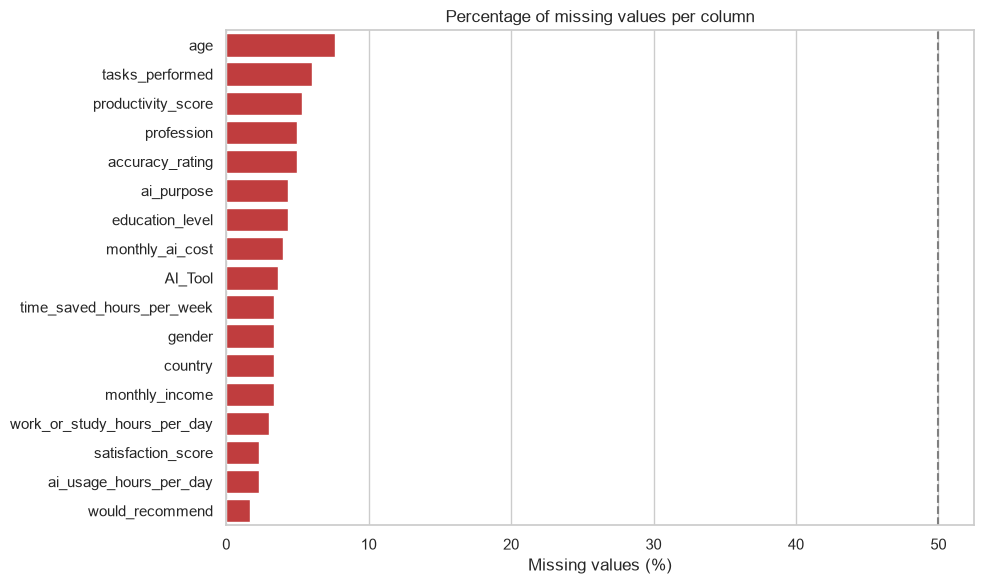

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()
# creates a bar plot visualizing the percentage of missing values for each column in the dataset that has at least one missing value, with a reference line at 50% to highlight columns with significant missing data. The plot is saved as a PNG image in the figures folder.
#NO HIGH PRC OF MISSING VALUES, CANNOT DROP ANY COLUMNS, WILL NEED TO IMPUTE MISSING VALUES

In [16]:
print(df["AI_Usage_Hours_Per_Day"].dtype)
# checks and prints the data type of the "AI_Usage_Hours_Per_Day" column to ensure it is in the correct format for analysis.

str


In [17]:
values = pd.to_numeric(df["AI_Usage_Hours_Per_Day"], errors="coerce")
print(df.loc[values.isna() & df["AI_Usage_Hours_Per_Day"].notna(),
             "AI_Usage_Hours_Per_Day"].unique())
# checks for any non-numeric values in the "AI_Usage_Hours_Per_Day" column by attempting to convert the values to numeric and identifying those that cannot be converted, printing the unique problematic entries.  

<StringArray>
[  '2 hrs',   '1 hrs', '1.6 hrs', '1.7 hrs', '2.2 hrs', '0.7 hrs', '9.9 hrs',
 '4.8 hrs', '1.3 hrs',   '5 hrs', '1.4 hrs', '0.6 hrs', '0.9 hrs', '0.8 hrs',
 '3.9 hrs', '4.9 hrs']
Length: 16, dtype: str


In [18]:
col = "AI_Usage_Hours_Per_Day"

cleaned = df[col].astype("string").str.strip()
cleaned = cleaned.str.replace(r"\s*(hours?|hrs?)$", "", regex=True, case=False)

converted = pd.to_numeric(cleaned, errors="coerce")

# See values that could not be converted
invalid = df.loc[converted.isna() & cleaned.notna() & cleaned.ne(""), col].unique()
print("Review these values:", invalid)

df[col] = converted
# converts the "AI_Usage_Hours_Per_Day" column to numeric values, handling any non-numeric entries by coercing them to NaN, and prints out any values that could not be converted for review.

Review these values: <StringArray>
[]
Length: 0, dtype: str


In [19]:
print(df["AI_Usage_Hours_Per_Day"].dtype)
#CHECKING TYPE OF COLUMN

Float64


In [20]:
print(df.dtypes)
#PRINTS THE DATA TYPES OF ALL COLUMNS IN THE DATASET TO VERIFY THAT THEY ARE APPROPRIATE FOR ANALYSIS.

User_ID                            str
Age                                str
Gender                             str
Country                            str
User_Type                          str
Education_Level                    str
Profession                         str
Monthly_Income                     str
AI_Tool                            str
AI_Purpose                         str
AI_Usage_Hours_Per_Day         Float64
Tasks_Performed                    str
Monthly_AI_Cost                    str
Productivity_Score             float64
Accuracy_Rating                float64
Satisfaction_Score             float64
Time_Saved_Hours_Per_Week          str
Work_or_Study_Hours_Per_Day        str
Would_Recommend                    str
dtype: object


In [21]:
cols = [
    "Work_or_Study_Hours_Per_Day",
    "Time_Saved_Hours_Per_Week",
    "Monthly_AI_Cost",
    "Monthly_Income",
]

hour_cols = [
    "Work_or_Study_Hours_Per_Day",
    "Time_Saved_Hours_Per_Week",
]

for col in cols:
    cleaned = df[col].astype("string").str.strip()
    cleaned = cleaned.str.replace(r"[$,]", "", regex=True)

    if col in hour_cols:
        cleaned = cleaned.str.replace(
            r"\s*(?:hrs?|hours?)\s*$", "", regex=True, case=False
        )

    df[col] = pd.to_numeric(cleaned, errors="raise").astype(float)

print(df[cols].dtypes)
# converts the specified columns to numeric values, cleaning them of any extraneous characters (like dollar signs, commas, or hour indicators) and ensuring they are in the correct format for analysis. It then prints the data types of these columns to confirm successful conversion.

Work_or_Study_Hours_Per_Day    float64
Time_Saved_Hours_Per_Week      float64
Monthly_AI_Cost                float64
Monthly_Income                 float64
dtype: object


In [22]:
print(df.dtypes)
#making sure all columns are in the correct format for analysis

User_ID                            str
Age                                str
Gender                             str
Country                            str
User_Type                          str
Education_Level                    str
Profession                         str
Monthly_Income                 float64
AI_Tool                            str
AI_Purpose                         str
AI_Usage_Hours_Per_Day         Float64
Tasks_Performed                    str
Monthly_AI_Cost                float64
Productivity_Score             float64
Accuracy_Rating                float64
Satisfaction_Score             float64
Time_Saved_Hours_Per_Week      float64
Work_or_Study_Hours_Per_Day    float64
Would_Recommend                    str
dtype: object


In [23]:
print(df[["Monthly_AI_Cost", "Monthly_Income"]].to_string(index=False))

 Monthly_AI_Cost  Monthly_Income
             NaN        5,421.00
            0.00        8,903.00
           20.00          402.00
           20.00        1,367.00
            0.00          438.00
            0.00          774.00
           20.00        4,466.00
            0.00          486.00
           30.00          132.00
           10.00        1,595.00
            0.00          856.00
            0.00          547.00
           10.00        3,307.00
           30.00          387.00
           10.00        3,117.00
           20.00          324.00
            0.00        3,546.00
           20.00          109.00
           20.00          109.00
           10.00          585.00
           10.00        1,977.00
           20.00            0.00
             NaN             NaN
           10.00            0.00
            0.00          444.00
           10.00          392.00
           10.00          215.00
            0.00        1,567.00
            0.00             NaN
          

In [24]:
students = df[
    df["User_Type"].astype("string").str.strip().str.casefold().eq("student").fillna(False)
]

total_students = len(students)

purpose_counts = (
    students["AI_Purpose"]
    .fillna("Missing / not reported")
    .value_counts()
    .rename_axis("AI purpose")
    .reset_index(name="Number of students")
)

purpose_counts["% of all students"] = (
    purpose_counts["Number of students"] / total_students * 100
).round(1)

print(f"Total students: {total_students}")
print(f"Distinct reported purposes: {students['AI_Purpose'].nunique()}")
display(purpose_counts)
# provides a summary of the purposes for which students use AI tools, including the total number of students, the count of distinct reported purposes, and a breakdown of the number and percentage of students for each purpose.

Total students: 151
Distinct reported purposes: 6


,AI purpose,Number of students,% of all students
0,Studying,39,25.80
1,Writing,29,19.20
2,Coding,28,18.50
3,Research,27,17.90
4,Content Creation,13,8.60
5,Missing / not reported,8,5.30
6,Data Analysis,7,4.60


In [25]:
students = df[
    df["User_Type"].astype("string").str.strip().str.casefold().eq("student").fillna(False)
].copy()

total_student_rows = len(students)
students["_response_row"] = range(total_student_rows)

# Identify missing or blank task responses
missing = (
    students["Tasks_Performed"].isna()
    | students["Tasks_Performed"].astype("string").str.strip().eq("").fillna(False)
)

# Split the comma-separated task descriptions into individual phrases
tasks = (
    students.loc[~missing, ["_response_row", "Tasks_Performed"]]
    .assign(Task=lambda x: x["Tasks_Performed"].astype("string").str.split(","))
    .explode("Task")
)

tasks["Task"] = tasks["Task"].astype("string").str.strip()
tasks = tasks[tasks["Task"].ne("")]

# Count each phrase once per student row
task_summary = (
    tasks.drop_duplicates(["_response_row", "Task"])
    .groupby("Task")
    .size()
    .sort_values(ascending=False)
    .rename("Number of student rows")
    .reset_index()
)

task_summary["% of student rows"] = (
    task_summary["Number of student rows"] / total_student_rows * 100
).round(1)

# Include missing responses as a reference row
missing_count = int(missing.sum())
if missing_count:
    task_summary.loc[len(task_summary)] = [
        "Missing / not reported",
        missing_count,
        round(missing_count / total_student_rows * 100, 1),
    ]

print(f"Total student rows: {total_student_rows}")
print(f"Distinct task phrases: {tasks['Task'].nunique()}")
display(task_summary)

Total student rows: 151
Distinct task phrases: 389


,Task,Number of student rows,% of student rows
0,Debugging code with AI assistance,12,7.90
1,Literature review and paper summarization,10,6.60
2,grammar checking and proofreading,8,5.30
3,research paper organization,7,4.60
4,creative writing brainstorming,6,4.00
...,...,...,...
385,Citation and referencing assistance,1,0.70
386,Code debugging and optimization,1,0.70
387,Code optimization and refactoring,1,0.70
388,solving differential equations,1,0.70


In [26]:
duplicate_ids = df[df["User_ID"].duplicated(keep=False)].sort_values("User_ID")

print("Rows with repeated User_IDs:", len(duplicate_ids))
print("Number of repeated User_IDs:", duplicate_ids["User_ID"].nunique())

display(duplicate_ids)

Rows with repeated User_IDs: 0
Number of repeated User_IDs: 0


,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend


#(AI usage hours vs. outcomes: 
Are more daily AI-use hours associated with higher productivity scores, satisfaction, accuracy ratings, or time saved?

Differences by user type: 
Do students and professionals report different usage, time savings, costs, or ratings?

AI purpose vs. outcomes:
Do people using AI for studying, coding, writing, or research report different productivity or satisfaction scores?

AI tool vs. ratings: 
Do reported outcomes vary by the AI tool used?
AI use and cost: Are more usage hours associated with higher monthly AI costs?

Income and AI cost: 
Does monthly AI cost vary with monthly income?
Ratings and recommendations: Are people with higher satisfaction, accuracy, or productivity scores more likely to recommend AI?

Background and usage: 
Do patterns differ by age, education level, profession, or country?)

Rows included: 267
Correlation: 0.6596859831026196


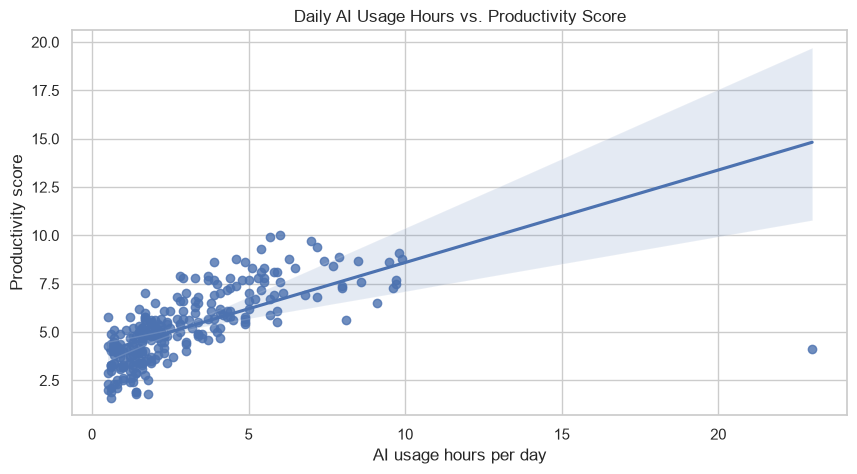

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Remove an optional "hrs"/"hours" suffix, then convert to numbers
hours = (
    df["AI_Usage_Hours_Per_Day"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s*(?:hrs?|hours?)\s*$", "", regex=True, case=False)
)

analysis = pd.DataFrame({
    "AI_Usage_Hours_Per_Day": pd.to_numeric(hours, errors="coerce"),
    "Productivity_Score": pd.to_numeric(df["Productivity_Score"], errors="coerce"),
}).dropna()

print("Rows included:", len(analysis))
print(
    "Correlation:",
    analysis["AI_Usage_Hours_Per_Day"].corr(analysis["Productivity_Score"])
)

sns.regplot(
    data=analysis,
    x="AI_Usage_Hours_Per_Day",
    y="Productivity_Score"
)
plt.title("Daily AI Usage Hours vs. Productivity Score")
plt.xlabel("AI usage hours per day")
plt.ylabel("Productivity score")
plt.show()
# creates a scatter plot with a regression line to visualize the relationship between daily AI usage hours and productivity scores, while also calculating and printing the correlation coefficient between these two variables.

Daily AI usage hours showed a moderately strong positive correlation with productivity scores (r = 0.66). This indicates an association, but does not establish causation.

Rows included: 271
Correlation: 0.7754083581110918


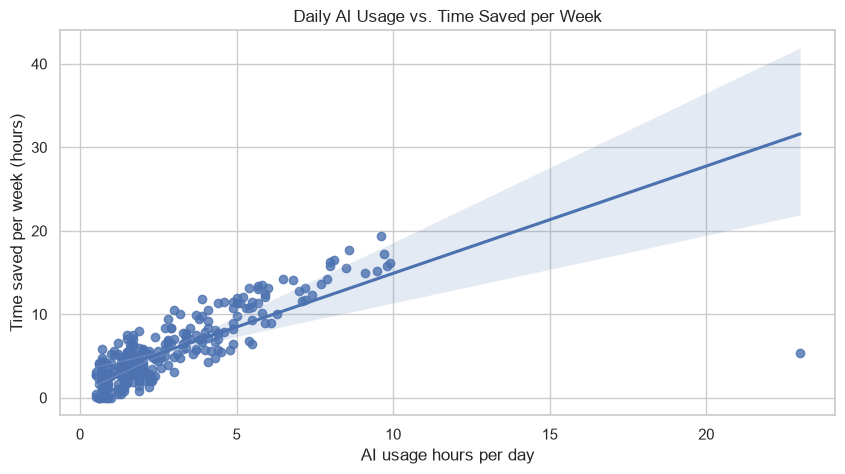

In [28]:
hours = (
    df["AI_Usage_Hours_Per_Day"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s*(?:hrs?|hours?)\s*$", "", regex=True, case=False)
)

time_saved = (
    df["Time_Saved_Hours_Per_Week"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s*(?:hrs?|hours?)\s*$", "", regex=True, case=False)
)

comparison = pd.DataFrame({
    "AI_Usage_Hours_Per_Day": pd.to_numeric(hours, errors="coerce"),
    "Time_Saved_Hours_Per_Week": pd.to_numeric(time_saved, errors="coerce"),
}).dropna()

print("Rows included:", len(comparison))
print("Correlation:", comparison["AI_Usage_Hours_Per_Day"].corr(
    comparison["Time_Saved_Hours_Per_Week"]
))

sns.regplot(
    data=comparison,
    x="AI_Usage_Hours_Per_Day",
    y="Time_Saved_Hours_Per_Week"
)
plt.title("Daily AI Usage vs. Time Saved per Week")
plt.xlabel("AI usage hours per day")
plt.ylabel("Time saved per week (hours)")
plt.show()

A correlation of 0.775 indicates a strong positive association: respondents who report more daily AI use also tend to report more hours saved per week. It doesn’t prove that AI use caused the time savings.

In [29]:
comparison["User_Type"] = df.loc[comparison.index, "User_Type"]

for user_type, group in comparison.groupby("User_Type"):
    correlation = group["AI_Usage_Hours_Per_Day"].corr(
        group["Time_Saved_Hours_Per_Week"]
    )
    print(f"{user_type} (n={len(group)}): correlation = {correlation:.3f}")

Professional (n=128): correlation = 0.608
Student (n=143): correlation = 0.923


Daily AI-use hours were positively correlated with reported weekly time saved for both students (r = 0.923, n = 143) and professionals (r = 0.608, n = 128). The association was stronger among students in this sample; these correlations alone do not establish causation or confirm a significant difference between groups.

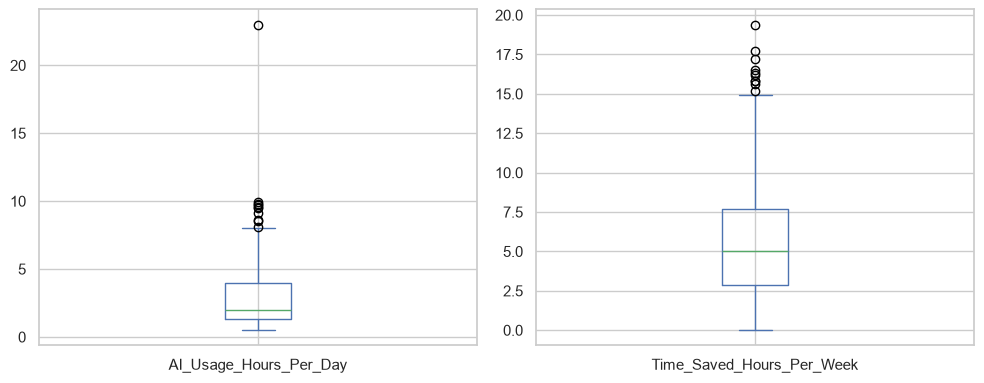

In [30]:
comparison[[
    "AI_Usage_Hours_Per_Day",
    "Time_Saved_Hours_Per_Week"
]].plot(kind="box", subplots=True, layout=(1, 2), figsize=(10, 4))

plt.tight_layout()
plt.show()
#

In [31]:
cols = ["AI_Usage_Hours_Per_Day", "Time_Saved_Hours_Per_Week"]
outlier_mask = pd.Series(False, index=comparison.index)

for col in cols:
    q1 = comparison[col].quantile(0.25)
    q3 = comparison[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    print(f"{col}: values below {lower:.2f} or above {upper:.2f} are flagged")
    outlier_mask |= (comparison[col] < lower) | (comparison[col] > upper)

display(comparison.loc[outlier_mask])
# identifies outliers in the "AI_Usage_Hours_Per_Day" and "Time_Saved_Hours_Per_Week" columns using the interquartile range (IQR) method, flags any values that fall below or above 1.5 times the IQR from the first and third quartiles, and displays the rows containing these outlier values for further review.

AI_Usage_Hours_Per_Day: values below -2.75 or above 8.05 are flagged
Time_Saved_Hours_Per_Week: values below -4.43 or above 14.98 are flagged


,AI_Usage_Hours_Per_Day,Time_Saved_Hours_Per_Week,User_Type
18,9.60,19.40,Student
19,23.00,5.40,Professional
46,9.10,14.90,Student
47,8.00,16.30,Professional
78,9.90,16.20,Professional
105,8.50,15.60,Professional
145,9.50,15.20,Student
188,9.80,15.80,Student
234,8.10,16.50,Professional
248,8.60,17.70,Student
